In [ ]:
%load_ext autoreload
%autoreload 2

In [6]:
import pandas as pd
import json
import matplotlib.pyplot as plt
import random
import seaborn as sns
from collections import Counter
from tqdm import tqdm
from features import limpiar_features_no_necesarias, transformar_features, transformar_target_a_estrellas, es_parte_de_saga, normalize_format, extraer_generos_libro

## 1. Comienzo por filtrar el dataset:

### 1.1 Primero saco las muestras de paises non-US:

In [ ]:
# chunks = pd.read_json("goodreads_books.json", lines=True, chunksize=100_000)

# us_list = []
# for chunk in chunks:
#     us_list.append(chunk[chunk["country_code"] == "US"])

# df_us = pd.concat(us_list, ignore_index=True)
# print(df_us.shape)


### 1.2 Ahora me tengo que quedar nomas con los libros que son en ingles:

Consideramos los libros en ingles los que tienen "languade_code" = ["en", "eng", "en-US", "en-GB", "en-CA", "enm", "ang", "sco", "gem"]

Las ultimas 4 opciones son ingles, pero antiguos (afectara en el rating del libro?... Acaso como a las personas de hoy en dia les cosatara mas atenderlo y por eso le daran bajo rating?...)

Tambien me quedo con las muestras con ese valor NaN, porque aun no podemos decidir si descartarlos o no.

In [ ]:
# valid_langs = {"en", "eng", "en-us", "en-gb", "en-ca", "enm", "ang", "sco", "gem"}
# lang = df_us["language_code"].fillna("").str.strip().str.lower()
# df_us_eng = df_us[lang.isin(valid_langs) | (lang == "")]
# print(df_us_eng.shape)

Lo guardo en un json:

In [ ]:
# import json
# output_path = "goodreads_us_english.json"
# chunk_size = 10000
# with open(output_path, "w", encoding="utf-8") as f:
#     for start in range(0, len(df_us_eng), chunk_size):
#         chunk = df_us_eng.iloc[start:start + chunk_size]
#         records = chunk.where(pd.notna(chunk), None).to_dict(orient="records")
#         for record in records:
#             json.dump(record, f, ensure_ascii=False)
#             f.write("\n")
# print("Guardado en", output_path)

Ahora abro el nuevo archivo que acabo de crear, asi trabajo sobre ese:

In [2]:
chunks2 = pd.read_json("goodreads_us_english.json", lines=True, chunksize=100_000)

chunk_list = []
for chunk in chunks2:
    chunk_list.append(chunk)

df_us_en = pd.concat(chunk_list, ignore_index=True)
print(df_us_en.shape)

(1925872, 29)


## 2. Reorganizo valores de features (breve inicio del preprocesamiento):

### 2.1 Comienzo por reagrupar los valores de "format"

In [3]:
# format_uniques = df_us_en["format"].unique()
# for v in format_uniques:
#     print(v)

In [4]:
# df_us_en["format"].value_counts().head(50)

In [5]:
mixed = df_us_en["format"].str.contains(
    "paperback.*ebook|ebook.*paperback|kindle.*paperback|paperback.*kindle",
    case=False,
    na=False
)

print(mixed.sum())

224


In [15]:
#Le aplico la funcion para reagrupar:
if "format_group" not in df_us_en.columns:
    df_us_en["format_group"] = df_us_en["format"].apply(normalize_format)

print(df_us_en["format_group"].value_counts())

format_group
PAPERBACK    683447
UNKNOWN      591456
EBOOK        293266
HARDCOVER    281921
AUDIO         67250
OTHER          7742
COMIC           790
Name: count, dtype: int64


In [8]:
df_us_en["format_group"].value_counts(normalize=True) * 100

format_group
PAPERBACK    35.487665
UNKNOWN      30.711075
EBOOK        15.227699
HARDCOVER    14.638616
AUDIO         3.491925
OTHER         0.402000
COMIC         0.041020
Name: proportion, dtype: float64

Mas o menos el 99.59% de las muestars quedaron clasificadas en categorias concretas --> esto esta muy bueno!
Y podemos ver que hay muhcos UNKOWNS, lo que signfica que el usuario no compleot la info

### 2.2 Convertimos "series" en una feature binaria

In [17]:
#is_series: feature binaria, true si es parte de una saga
df_us_en["is_series"] = df_us_en["series"].apply(es_parte_de_saga)
df_us_en = df_us_en.drop(columns = ["series"])

## 3. Analizo features (EDA):

### 3.1 Analisando el target

In [ ]:
df_us_en["average_rating"] = pd.to_numeric(df_us_en["average_rating"], errors='coerce')
print(df_us_en["average_rating"].isna().sum())
print(df_us_en["average_rating"].max())
print(df_us_en["average_rating"].min())

En este sample, hay XX libros sin rating. Corresponde al XXX%. Podemos eliminar esos libros. Notamos aparte que no hay outliers. --> SIGUE EN PIE ESTO CON TODO EL DATASET???

In [ ]:
df_us_en = df_us_en.dropna(subset=["average_rating"])
target_regresion = df_us_en["average_rating"]
target_clasificacion = transformar_target_a_estrellas(target_regresion)

In [ ]:
df_us_en["average_rating"].describe()

Como lo van a confirmar los graficos mas adelante, la mayoria de ratings se encuentran entre 3.5 y 4.5. 

In [ ]:
df_us_en["stars"].value_counts(normalize=True).sort_index()

El desbalanceo de clases se hace aun mas presente en el target para clasificacion.

In [ ]:
target_clasificacion_balanceado = pd.qcut(df_us_en["average_rating"], q=5)
print(target_clasificacion_balanceado.value_counts().sort_index())

Esta estrategia permitiria mantener 5 clases balanceadas, pero perdemos la interpretabilidad de las 5 estrellas. 

In [ ]:
plt.hist(df_us_en["average_rating"], bins=50)
plt.xlabel("Average Rating")
plt.ylabel("Cantidad de libros")
plt.title("Distribución de ratings")
plt.show()

plt.boxplot(df_us_en["average_rating"])
plt.ylabel("Average Rating")
plt.show()

In [ ]:
df_us_en["stars"] = df_us_en["average_rating"].round().astype(int)
df_us_en["stars"].value_counts().sort_index().plot(kind="bar")

plt.title("Distribución de estrellas")
plt.show()

### 3.2 Veo cuantas muestras tienen el laguage_code incompleto:

In [9]:
missing = df_us_en["language_code"].isna().sum() #Aplica para NaN y None
empty_str = (df_us_en["language_code"] == "").sum()
print("NaN:", missing)
print("Cadena vacía:", empty_str)
print("Total vacío:", missing + empty_str)

NaN: 0
Cadena vacía: 1059663
Total vacío: 1059663


Tiene sentido que hayan 0 NaN, porque cuando adquirimos las muestras para armar el dataset actual, convertimos los NaN en stirngs vacios (para veitar warnings)

### 3.3 ¿El formato del libro tiene alguna relacion con el rating?

In [12]:
#df_us_en.groupby("format_group").apply(lambda x: pd.to_numeric(x["average_rating"], errors="coerce").mean())

In [18]:
df_us_en["average_rating"] = pd.to_numeric(df_us_en["average_rating"], errors="coerce")
df_us_en.groupby("format_group")["average_rating"].agg(["count", "mean", "std"])

,count,mean,std
format_group,,,
AUDIO,67250,3.904904,0.326185
COMIC,790,3.891291,0.447508
EBOOK,293266,3.910180,0.530976
HARDCOVER,281921,3.836821,0.522361
OTHER,7742,3.847796,0.610235
PAPERBACK,683447,3.883242,0.507260
UNKNOWN,591450,3.896092,0.574507


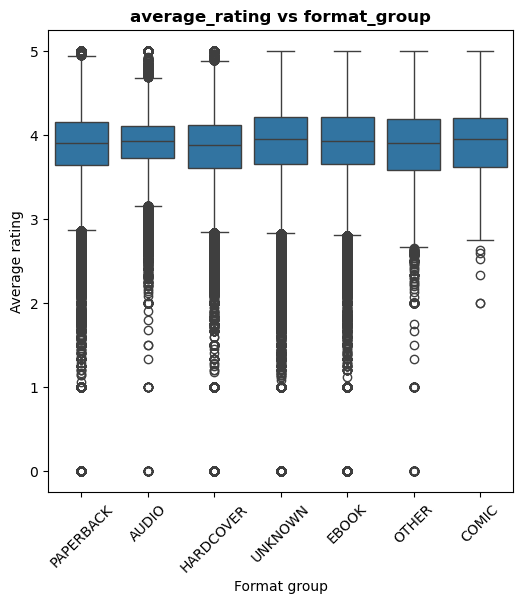

In [19]:
plt.figure(figsize = (6, 6))
sns.boxplot(data = df_us_en, x = "format_group", y = "average_rating")
plt.xlabel("Format group")
plt.ylabel("Average rating")
plt.title("average_rating vs format_group", fontweight = "bold")
plt.xticks(rotation = 45)
plt.show()

Visualmente todas las lineas (meidanas) quedaron casi a la misma altura. Esto sugiere que Ee rating tipico de los libros es muy parecido independientemente del formato. 

Y como las cajas tienen tamaños similares, eso indica que la dispersion de los ratings tambien es parecida.

Ahora, como la cantidad de muestras por categoria es muy significativa, tambien hay que analizar los valores estadisitcos (de la tabla de arriba):

En cuanto al mean --> La diferencia entre el mas alto y el mas bajo es: 3.910 - 3.837 = 0.073. Entonces, si bien existen pequeñas diferencias entre categorias, los valores medios de average_rating son muy similares para todos los formatos que estamos analizando. Esto sugiere que el formato de publicacion no presenta una relacion fuerte con la valoracion promedio de los libros.

En cuanto al std --> Los audiolibros tienen una dispersion bastante menor. Esto podria indicar que los audiolibros suelen recibir ratings mas consistentes, o que hay menos titulos de muy baja valoración dentro de AUDIO.

### 3.4 La variable is_ebook, es util teniendo en cuenta que vamos a hacer un one hot encoding a la nueva feature de format_group?

### 3.5 "series"

In [ ]:
df_us_en["series"].str.len().value_counts().sort_index()

La feature "series" contiene una lista. Si la lista esta vacia el libro no es parte de una saga. No tiene valores Nan o que no sean una lista. --> esto ultimo se mantiene con este nuevo dataset???

### 3.6 "publication_year" y "num_pages"

In [7]:
df_us_en[["publication_year","num_pages"]].describe()
df_us_en["publication_year"] = pd.to_numeric(df_us_en["publication_year"], errors='coerce')
df_us_en["num_pages"] = pd.to_numeric(df_us_en["num_pages"],errors='coerce')
df_us_en[["publication_year","num_pages"]].describe()

print(df_us_en["num_pages"].isna().sum())
print(df_us_en["publication_year"].isna().sum())

708969
548373


Noto que hay que tratar con varios nan en publication year y num pages. Hay que decidir como tratar eso.

##### Analizando "num_pages"

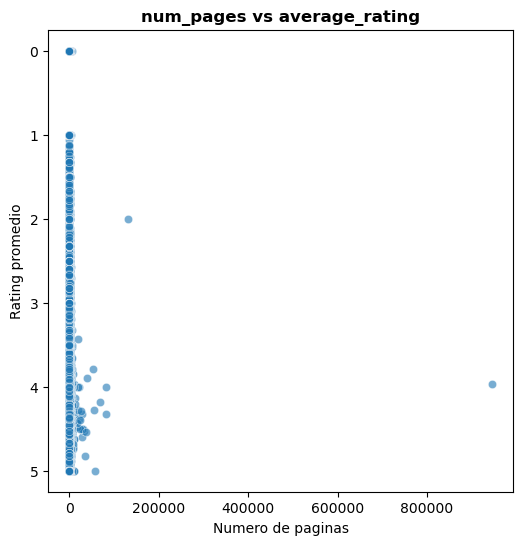

In [12]:
plt.figure(figsize = (6, 6))
sns.scatterplot(data = df_us_en, x = "num_pages", y = "average_rating", alpha = 0.6)
plt.xlabel("Numero de paginas")
plt.ylabel("Rating promedio")
plt.title("num_pages vs average_rating", fontweight = "bold")
plt.show()

Definitvamente hay outliers -> considero que habria que elimina rlos puntos que superan una cantidad ridicula de paginas

Vemos que para una misma aprox cantidad de hojas el rating varia muchismo (adopta casi todo los valores posibles) --> no sera una feature que por si sola determine mucho el target

Quiero cheqeuar el min y max de cantidad de hojas (porque no tendria sentido, por ejemplo, un libro con 0 hojas...)

In [11]:
print(df_us_en["num_pages"].max())
print(df_us_en["num_pages"].min())

945077.0
0.0


Definitivamente vamos a tener que eliminar outliers y valores ilogicos... 

##### Analizando "publication_year"

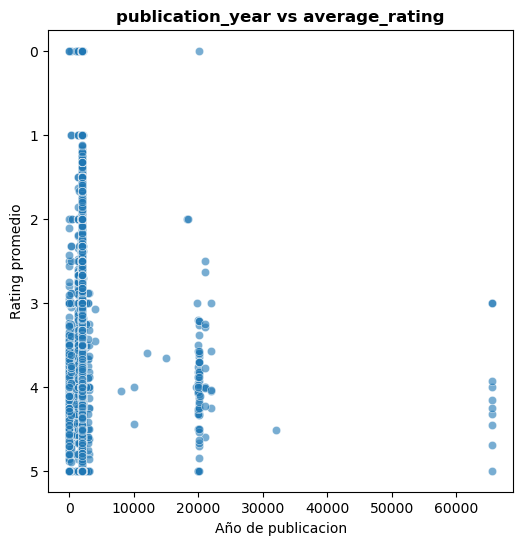

In [13]:
plt.figure(figsize = (6, 6))
sns.scatterplot(data = df_us_en, x = "publication_year", y = "average_rating", alpha = 0.6)
plt.xlabel("Año de publicacion")
plt.ylabel("Rating promedio")
plt.title("publication_year vs average_rating", fontweight = "bold")
plt.show()

Al igual que con "num_pages", a esta escala, pareceria que la feature no es muy relevante para el target. Y posee MUCHOS mas outliers que "num_pages". Mas bien, son valores mal cargados, porque no tiene sentido que el año de publicacion sea mas grande que 2026...

Veamos en un escala mas chica (rango de años mas razonable):

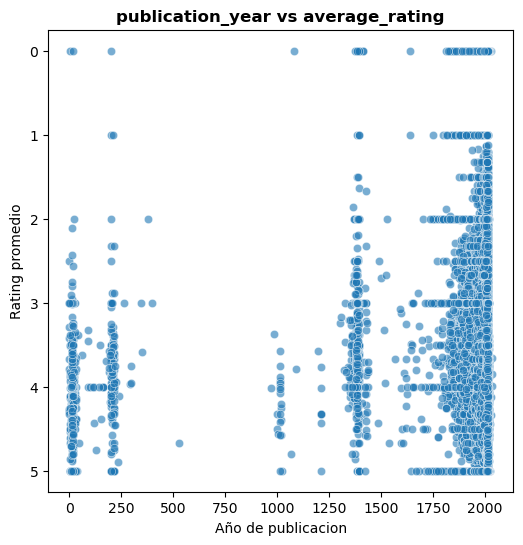

In [14]:
df_filtrado_publi_year = df_us_en[df_us_en["publication_year"] <= 2040]

plt.figure(figsize = (6, 6))
sns.scatterplot(data = df_filtrado_publi_year, x = "publication_year", y = "average_rating", alpha = 0.6)
plt.xlabel("Año de publicacion")
plt.ylabel("Rating promedio")
plt.title("publication_year vs average_rating", fontweight = "bold")
plt.show()

Definitivamente a simple vista no se puede identificar una fuerte realcion entre el targte y esta variable, pero seguimos descubirendo posible outliers... --> Como son los titulos de tiene año de publicacion cerca de cero? Porque si son antiguos tendria sentido, pero sino, son datos mal registrados...

### 3.7 Buscando la feature "genero"

In [3]:
for i in range(5):
    print(f"Libro {i}")
    print(df_us_en["popular_shelves"].iloc[i])
    print()

from collections import Counter

counter = Counter()

for shelves in df_us_en["popular_shelves"]:
    for shelf in shelves:
        counter[shelf["name"]] += 1

Libro 0
[{'count': '3', 'name': 'to-read'}, {'count': '1', 'name': 'p'}, {'count': '1', 'name': 'collection'}, {'count': '1', 'name': 'w-c-fields'}, {'count': '1', 'name': 'biography'}]

Libro 1
[{'count': '2634', 'name': 'to-read'}, {'count': '160', 'name': 'fiction'}, {'count': '92', 'name': 'currently-reading'}, {'count': '25', 'name': 'contemporary-fiction'}, {'count': '22', 'name': 'owned'}, {'count': '19', 'name': 'book-club'}, {'count': '17', 'name': 'chick-lit'}, {'count': '16', 'name': 'friendship'}, {'count': '15', 'name': 'books-i-own'}, {'count': '12', 'name': 'novel'}, {'count': '12', 'name': 'general-fiction'}, {'count': '11', 'name': 'anita-diamant'}, {'count': '10', 'name': 'owned-books'}, {'count': '10', 'name': 'contemporary'}, {'count': '10', 'name': 'women'}, {'count': '8', 'name': 'adult'}, {'count': '7', 'name': 'default'}, {'count': '7', 'name': 'favorites'}, {'count': '7', 'name': 'didn-t-finish'}, {'count': '6', 'name': 'own-it'}, {'count': '6', 'name': 'librar

In [ ]:
counter.most_common(200)

In [ ]:
genres = ["fiction", "romance", "contemporary", "adult", "non-fiction", "fantasy", "mystery", "novels", "history", "nonfiction", "historical", "young-adul", "novel", "historical-fiction", "adult-fiction", "adventure", "literature", "classics", "thriller", "ya", "suspense", "paranormal", "science-fiction", "crime", "drama", "sci-fi", "contemporary-romance", "general-fiction", "contemporary-fiction", "childrens", "children", "mystery-thriller", "classic", "biography", "sci-fi-fantasy", "horror", "mysteries", "magic", "children-s", "mystery-suspense", "philosophy", "science", "erotica", "literary", "fantasy-sci-fi", "religion", "scifi", "politics", "memoir", "paranormal-romance", "thrillers", "psychology", "ya-fiction", "crime-fiction", "juvenile"]

In [4]:
chunks = pd.read_json("goodreads_us_english.json", lines=True, chunksize=100_000)
contador = Counter()
for chunk in tqdm(chunks):
    for shelves in chunk["popular_shelves"]:
        for shelf in shelves:
            contador[shelf["name"]] += int(shelf["count"])
contador.most_common(2000)

20it [04:35, 13.77s/it]


[('to-read', 4930080153),
 ('currently-reading', 323505192),
 ('favorites', 168678540),
 ('classics', 146774656),
 ('fiction', 141499351),
 ('fantasy', 102357451),
 ('young-adult', 50212844),
 ('books-i-own', 46063532),
 ('owned', 44305203),
 ('romance', 35051523),
 ('historical-fiction', 29878626),
 ('classic', 29488169),
 ('mystery', 28156117),
 ('science-fiction', 24721369),
 ('ya', 22845326),
 ('non-fiction', 22126972),
 ('sci-fi', 19853644),
 ('series', 19845219),
 ('kindle', 18881784),
 ('favourites', 17031116),
 ('literature', 16159710),
 ('owned-books', 15454073),
 ('horror', 14479657),
 ('book-club', 13415393),
 ('default', 13375681),
 ('library', 12842717),
 ('contemporary', 12058307),
 ('audiobook', 11931285),
 ('paranormal', 11678342),
 ('novels', 11649309),
 ('to-buy', 11467827),
 ('historical', 11366849),
 ('childrens', 11091620),
 ('adventure', 10574054),
 ('adult', 10274829),
 ('ebook', 9944791),
 ('history', 9868281),
 ('audiobooks', 9692662),
 ('nonfiction', 9510917),

In [5]:
df_us_en["genres"] = df_us_en["popular_shelves"].apply(extraer_generos_libro)
sin_genero = (df_us_en["genres"].str.len() == 0).sum()
print(f"{100*sin_genero/len(df_us_en):.2f}%")

12.35%


## 4. Continuamos el preprocesamiento (se empezo un poco antes del EDA):

In [ ]:
df_procesado = transformar_features(df_us_en)
df_entrenamiento = limpiar_features_no_necesarias(df_procesado)

# TODO

saga func clari , incluye rautng graf

autores agrupar para luego inflkuye rating graf 